# 1. Descripción del Problema:



#### Tienes 8 puntos de entrega físicos. Algunos pares entran en conflicto (rutas que se solapan, ventanas horarias incompatibles, comparten lugar de carga...). El peso de la arista es el coste del conflicto. Quieres repartir los puntos entre dos turnos (o dos vehículos) de modo que se separen los conflictos más caros.

#### Este problema se puede afrontar como MaxCut Problem con pesos: maximizar el peso total de los conflictos que quedan entre turnos distintos.

(Cabe destacar que el enrutamiento de un problema real es un VRP, y esto solo supone una abstracción)

## 1.1 Definición del Escenario


#### Cada arista será una tupla (i, j, peso). Por ejemplo, (1, 3, 4) significa que los nodos 1 y 3 están conectados con un peso de 4. En el cuadrado todos los pesos valen 1, así que equivale a contar aristas.


In [2]:
!pip install networkx matplotlib numpy -q

In [3]:
import itertools
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

SEED = 42

# Las listas de aristas. Cada arista es una tupla (i, j, peso).
# Por ejemplo, (1, 3, 4) significa “los nodos 1 y 3 están conectados con peso 4”. En el cuadrado todos los pesos valen 1, así que equivale a contar aristas.

# --- Grafo de prueba (para validarlo en papel): cuadrado sin pesos ---
# Esto es para hacerlo a papel, y ver si sale bien, de cara a escribir la función que se encargue de resolver el grafo.
square_edges = [(0, 1, 1), (1, 2, 1), (2, 3, 1), (3, 0, 1)]

# --- Escenario logístico: 8 puntos de entrega, aristas = conflictos con coste ---
# Es el problema real representado como grafo a solucionar. Al principio solo me encargaré del grafo anterior, square_edges.
conflicts = [
    (0, 1, 3), (0, 2, 1), (1, 2, 2), (1, 3, 4),
    (2, 4, 2), (3, 4, 3), (3, 5, 1), (4, 5, 2),
    (4, 6, 3), (5, 7, 2), (6, 7, 4), (0, 7, 1),
]

In [4]:
def build_graph(edges):
    """Construye un grafo no dirigido. Recibe el argumento 'edges' para construirlo"""
    G = nx.Graph()  #crea un grafo no dirigido.
    G.add_weighted_edges_from(edges)  #añade todas las aristas y guarda el tercer elemento de cada tupla como atributo weight.
    return G


def draw_graph(G, x=None, title=""):
    """Dibuja el grafo. Si pasamos un bitstring x (por defecto, None) como lista de 0/1 por nodo,
    colorea los nodos por grupo y resalta en rojo las aristas cortadas."""
    pos = nx.spring_layout(G, seed=SEED) #asigna las posiciones de los nodos en el plano. Con distintas semillas, varia.
    if x is None:
        node_colors, edge_colors = "lightgray", "gray"
    else:
        node_colors = ["tab:blue" if x[n] == 0 else "tab:orange" for n in G.nodes]
        edge_colors = ["red" if x[u] != x[v] else "lightgray" for u, v in G.edges]
    nx.draw(G, pos, with_labels=True, node_color=node_colors,
            edge_color=edge_colors, width=2, node_size=600)
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "weight"))
    plt.title(title)
    plt.show()

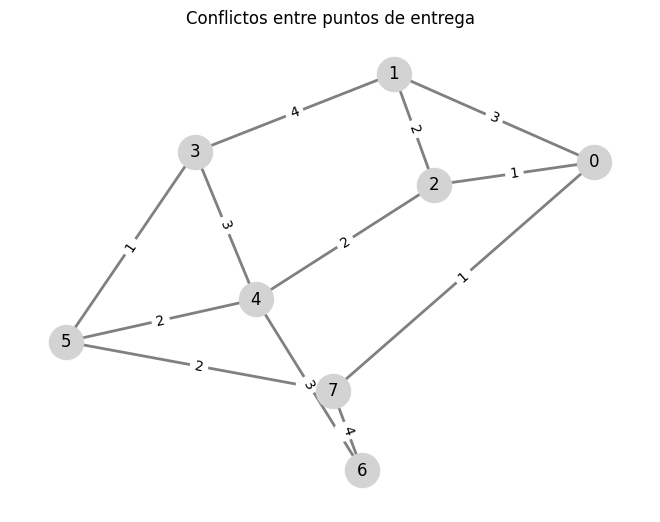

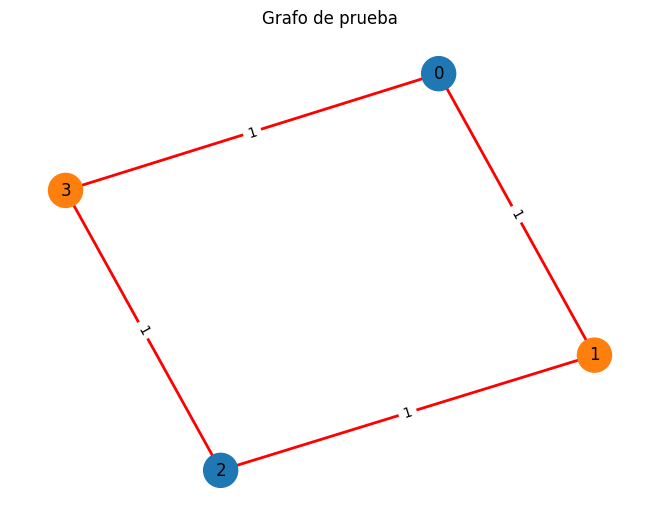

In [5]:
G_square = build_graph(square_edges)
G = build_graph(conflicts)

draw_graph(G, title="Conflictos entre puntos de entrega")
draw_graph(G_square, x=[0, 1, 0, 1], title="Grafo de prueba")
# x=[0, 0, 1, 1]. Probar con este bitstring también.
# ¿Cuántas aristas salen en rojo en cada caso, y qué te dice eso sobre cuál es mejor reparto?

### 1.1.2 ¿Para qué sirven las siguientes funciones, cut_value() y brute_force()?

Cuando QAOA funcione, lo que nos devolverá nuestro circuito, al medir, será un bitstring, por ejemplo 01010101. Ese bitstring es un reparto de los 8 puntos de entrega. Pero para comprobar cómo de buena es la solución dada por el QAOA, necesitamos:

- **cut_value**: la nota de un reparto. Le pasamos un bitstring y nos dice cuánto peso de conflictos separa. Después de medir el circuito miles de veces, puntuamos cada bitstring con esta función.
- **brute_force**: la nota máxima posible. Con 8 nodos solo hay 256 repartos, así que probamos todos y nos quedamos con el mejor. Es nuestra verdad de referencia: sin ella no podemos decir si QAOA lo hizo bien o mal.

En resumen, el circuito propone repartos, de tal forma que *cut_value* los puntúa, y *brute_force* nos dice cuál es la puntuación máxima.

In [6]:
def cut_value(x, edges):
    """ OBJETIVO: Medir cómo de bueno es un bitstring (x, que será generado por el QAOA) para un grafo dado (edges), y darle una puntuación.
        Argumento 1 (x): bitstring que es una lista/tupla de 0's o 1's (0-> grupo A , 1-> grupo B). El orden de esta lista debe coincidir con el orden de los nodos en el grafo. Es decir, x[0] es el nodo 0, x[1] es el nodo 1, etc.
        Argumento 2 (edges): lista de (i, j, peso).
        Devuelve: el peso total de las aristas cortadas."""
    # TODO
    # Recordemos. Por ejemplo, (1, 3, 4) significa “los nodos 1 y 3 están conectados con peso 4”.
    total = 0
    for i, j, w in edges:
        # ¿cuándo está cortada la arista (i, j)?
        if x[i] != x[j]:
            # si está cortada, ¿qué peso tiene?
            total += w
    return total


def brute_force(n, edges):
    """ OBJETIVO: Recorre los 2^n bitstrings, y calcula la nota máxima posible. Pruebo todos porque son solo 8 nodos, o 256 repartos. Servirá para decir si QAOA lo hizo bien o mal.
        Argumento 1 (n): número de nodos.
        Argumento 2 (edges): lista de (i, j, peso).
        Devuelve: (mejor_valor, lista_de_todos_los_bitstrings_óptimos).
    """
    # Son cuatro ideas: generar todos los bitstrings, puntuar cada uno con cut_value, quedarnos con el mayor valor y guardar todos los bitstrings que lo alcanzan.
    best_value = -1
    best_xs = []

    for i in range(2**n):
      bin_string = format(i, f"0{n}b") #convierte i en un texto binario de n digitos. Para 4 digitos, sería 04b...
      bin_list = list(bin_string)  # Por ejemplo, pasaríamos de "0110" a ["0", "1", "1", "0"]
      bin_list = [int(bit) for bit in bin_list] #de string a int. Es decir, pasamos de ["0", "1", "1", "0"] a [0,1,1,0].

      res = cut_value(bin_list, edges)

      if res > best_value:
        best_value = res
        best_xs = [bin_list]
      elif res == best_value:
        best_xs.append(bin_list)

    return (best_value, best_xs)


4 2 0
4 [[0, 1, 0, 1], [1, 0, 1, 0]]
26 [[0, 1, 0, 0, 1, 0, 0, 1], [1, 0, 1, 1, 0, 1, 1, 0]]


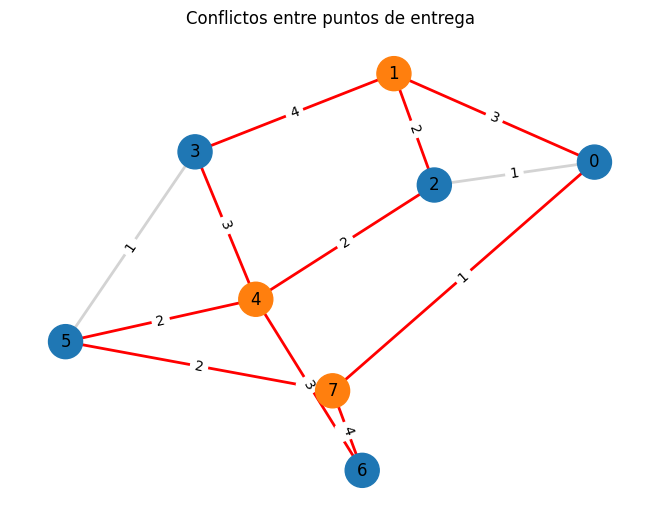

In [7]:
res1 = cut_value([0, 1, 0, 1], square_edges) #debería dar 4.
res2 = cut_value([0, 0, 1, 1], square_edges) #debería dar 2.
res3 = cut_value([0, 0, 0, 0], square_edges) #debería dar 0. Pensemos por qué. 0,0,0,0 quiere decir que, todos los nodos sean del mismo grupo. Por tanto, no hay ni una sola arista cortante.
print(res1, res2, res3)

weights, xs_list = brute_force(4, square_edges)
print(weights, xs_list)
weights, xs_list = brute_force(8, conflicts)
print(weights, xs_list)

# Los resultados tienen sentido.

G = build_graph(conflicts)
draw_graph(G, xs_list[0], title="Conflictos entre puntos de entrega")

## 2. Explicación: de MaxCut a Ising

**La idea** clave es que el circuito cuántico que vamos a diseñar, no trabajará con los valores 0 y 1 de nuestros bitstrings de antes, sino con los valores propios de la puerta $Z$, que son $+1$ y $-1$. Por eso, podemos hacer un cambio de variable: $z_i = 1 - 2 x_i$ (grupo A $\rightarrow +1$, grupo B $\rightarrow -1$).

**Para cada arista,** el producto $z_i z_j$ responde a la pregunta "¿están los dos nodos en el mismo grupo?": vale $+1$ si coinciden (arista sin cortar) y $-1$ si difieren (arista cortada). Con eso, la indicadora de corte se escribe como:

$$\text{cortada}(i,j) = \frac{1 - z_i z_j}{2}$$

(si $z_i z_j = +1$ da $0$, y si $z_i z_j = -1$ da $1$).

**El grafo entero.** Sumamos sobre todas las aristas multiplicando por su peso, con $W = \sum w_{ij}$ (el peso total del grafo). La suma de los términos constantes da $W/2$, y queda solo una parte que depende del reparto:

$$\text{cut}(z) = \frac{W}{2} - \frac{1}{2} \sum w_{ij} z_i z_j \implies \text{cut} = \frac{W - E}{2}, \quad \text{donde} \quad E(z) = \sum w_{ij} z_i z_j$$

**Maximizar el corte equivale a minimizar la energía $E$.** Como $W$ es constante y $E$ va con signo negativo, cuanto menor sea $E$, mayor es el corte. A $E(z)$ la llamamos "energía" porque este problema tiene la forma de un modelo de Ising de la física, donde el estado de menor energía es el más estable.

**Paso al circuito.** Cada variable $z_i$ se sustituye por la puerta $Z$ del cúbit $i$, y $E$ se convierte en el Hamiltoniano $H = \sum w_{ij} Z_i Z_j$. Como $H$ solo contiene puertas $Z$, es diagonal en la base computacional: la "energía" de cada bitstring es justo el valor que calculamos con `ising_energy`, y por eso podemos validarlo contra la fuerza bruta.

In [8]:
def ising_energy(x, edges):
    z = [1 - 2 * b for b in x]
    return sum(w * z[i] * z[j] for i, j, w in edges)

def check_ising(n, edges):
    W = sum(w for _, _, w in edges)
    for x in itertools.product([0, 1], repeat=n):
        assert cut_value(x, edges) == (W - ising_energy(x, edges)) / 2, x
    print(f"OK: cut = (W - E)/2 en los {2**n} bitstrings")

check_ising(4, square_edges)
check_ising(8, conflicts)

W = sum(w for _, _, w in conflicts)
E_min = min(ising_energy(x, conflicts) for x in itertools.product([0, 1], repeat=8))
print(f"W = {W}, energia minima = {E_min}, corte optimo = (W - E_min)/2 = {(W - E_min)/2}")

OK: cut = (W - E)/2 en los 16 bitstrings
OK: cut = (W - E)/2 en los 256 bitstrings
W = 28, energia minima = -24, corte optimo = (W - E_min)/2 = 26.0


## 3. QAOA desde cero (simulador de vector de estado)

Un estado de $n$ cúbits es un vector de $2^n$ amplitudes complejas. Como el operador de coste $H$ es diagonal en la base computacional, guardamos solo su diagonal: el **valor del corte de cada bitstring**.

El circuito de $p$ capas parte de $|+\rangle^{\otimes n}$ y repite:

* **Capa de coste** $e^{-i \gamma H}$: multiplica cada amplitud por una fase que depende de su energía. En puertas son compuertas $\text{RZZ}(2\gamma w)$ por cada arista del grafo.
* **Capa de mezclador** $e^{-i \beta \sum X}$ en cada cúbit (aplicando puertas $\text{RX}(2\beta)$): mezcla amplitudes entre diferentes estados computacionales mediante interferencia.

Un optimizador clásico ajusta los parámetros $(\gamma, \beta)$ de forma iterativa para **maximizar el valor esperado del corte** $\langle \text{cut} \rangle$.

La capa de coste crea diferencias de fase entre los bitstrings según la calidad de su energía, y la capa de mezclador traduce esas diferencias de fase en interferencia constructiva y destructiva, elevando la probabilidad de obtener los mejores repartos al medir.

*Convención de bits:* el índice $i$ del vector de estado tiene el bit correspondiente al nodo $0$ como el **más significativo** (MSB), coincidiendo exactamente con el orden generado por `itertools.product` y con la función `format(i, "0nb")` utilizada en la fuerza bruta (`brute_force`).

In [13]:
import itertools, time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import minimize


def cost_vectors(n, edges):
    """Devuelve (cut[i], E[i]) para los 2^n bitstrings, i = indice con nodo 0 como bit mas significativo."""
    idx = np.arange(2**n)
    bits = (idx[:, None] >> np.arange(n - 1, -1, -1)) & 1
    cut = np.zeros(2**n)
    for i, j, w in edges:
        cut += w * (bits[:, i] != bits[:, j])
    W = sum(w for _, _, w in edges)
    return cut, W - 2 * cut          # E = W - 2*cut

def apply_mixer(psi, beta, n):
    c, s = np.cos(beta), -1j * np.sin(beta)
    U = np.array([[c, s], [s, c]])
    psi = psi.reshape((2,) * n)
    for k in range(n):
        psi = np.moveaxis(np.tensordot(U, psi, axes=([1], [k])), 0, k)
    return psi.reshape(-1)

def qaoa_state(params, n, E):
    p = len(params) // 2
    gammas, betas = params[:p], params[p:]
    psi = np.full(2**n, 1 / np.sqrt(2**n), dtype=complex)      # |+>^n
    for g, b in zip(gammas, betas):
        psi = psi * np.exp(-1j * g * E)                         # capa de coste
        psi = apply_mixer(psi, b, n)                            # capa de mezcla
    return psi

# Sanity checks del simulador
cut8, E8 = cost_vectors(8, conflicts)
opt, xs_opt = brute_force(8, conflicts)   # corte óptimo (26) y sus bitstrings óptimos
assert cut8.max() == opt
assert abs(np.linalg.norm(qaoa_state(np.array([0.7, 0.3]), 8, E8)) - 1) < 1e-12   # unitario
assert np.isclose(cut8.mean(), (np.abs(qaoa_state(np.zeros(2), 8, E8))**2 * cut8).sum())  # params=0 -> uniforme
print("Simulador OK. Corte esperado de un reparto aleatorio:", round(cut8.mean(), 3), "| optimo:", opt)

Simulador OK. Corte esperado de un reparto aleatorio: 14.0 | optimo: 26


In [14]:
def run_qaoa(n, edges, p, restarts=8, maxiter=300, seed=0):
    """Optimiza (gamma, beta) con COBYLA y varios reinicios. Devuelve un dict con resultados y recursos."""
    rng = np.random.default_rng(seed)
    cut, E = cost_vectors(n, edges)
    opt_val = cut.max()
    evals = 0

    def neg_expected_cut(params):
        nonlocal evals
        evals += 1
        probs = np.abs(qaoa_state(params, n, E))**2
        return -(probs @ cut)

    t0 = time.perf_counter()
    best = None
    for _ in range(restarts):
        x0 = np.concatenate([rng.uniform(0, np.pi, p), rng.uniform(0, np.pi / 2, p)])
        r = minimize(neg_expected_cut, x0, method="COBYLA", options={"maxiter": maxiter})
        if best is None or r.fun < best.fun:
            best = r
    elapsed = time.perf_counter() - t0

    probs = np.abs(qaoa_state(best.x, n, E))**2
    shots = 1024
    samples = rng.choice(2**n, size=shots, p=probs / probs.sum())
    return {
        "params": best.x,
        "approx_ratio": -best.fun / opt_val,                   # <cut> / optimo
        "best_sample_ratio": cut[samples].max() / opt_val,     # mejor de 1024 shots / optimo
        "p_optimal": probs[cut == opt_val].sum(),              # prob. de medir un optimo
        "time": elapsed, "evals": evals, "p": p, "qubits": n, "probs": probs,
    }

for p in (1, 2, 3):
    r = run_qaoa(8, conflicts, p, seed=1)
    print(f"p={p}: <cut>/opt = {r['approx_ratio']:.3f} | mejor de 1024 shots = {r['best_sample_ratio']:.3f} "
          f"| P(optimo) = {r['p_optimal']:.3f} | evals = {r['evals']} | {r['time']:.1f}s")

p=1: <cut>/opt = 0.752 | mejor de 1024 shots = 1.000 | P(optimo) = 0.106 | evals = 474 | 1.0s
p=2: <cut>/opt = 0.754 | mejor de 1024 shots = 1.000 | P(optimo) = 0.102 | evals = 1476 | 5.5s
p=3: <cut>/opt = 0.773 | mejor de 1024 shots = 1.000 | P(optimo) = 0.186 | evals = 2361 | 7.2s


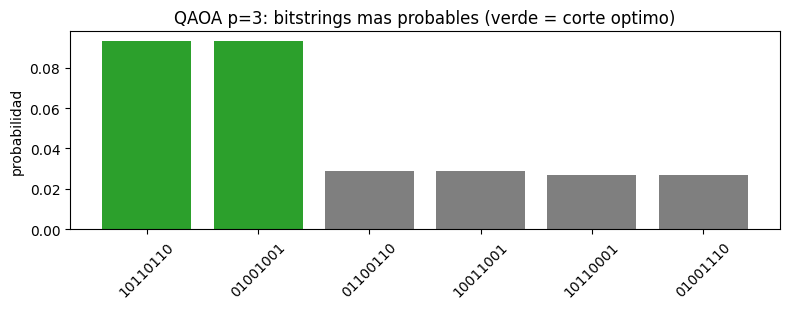

In [15]:
r = run_qaoa(8, conflicts, p=3, seed=1)
order = np.argsort(r["probs"])[::-1][:6]
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = [format(i, "08b") for i in order]
colors = ["tab:green" if cut8[i] == opt else "tab:gray" for i in order]
ax.bar(labels, r["probs"][order], color=colors)
ax.set_ylabel("probabilidad"); ax.set_title("QAOA p=3: bitstrings mas probables (verde = corte optimo)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 4. Baseline clasico para comparar: Simulated Annealing

Heuristica estandar: voltear un nodo al azar, aceptar si mejora o con probabilidad `exp(delta/T)` si empeora,
enfriando `T` poco a poco. Contamos sus **evaluaciones de corte** para comparar presupuestos.

In [16]:
def simulated_annealing(n, edges, steps=2000, T0=2.0, T1=0.05, seed=0):
    rng = np.random.default_rng(seed)
    adj = [[] for _ in range(n)]
    for i, j, w in edges:
        adj[i].append((j, w)); adj[j].append((i, w))
    x = rng.integers(0, 2, n)
    cur = cut_value(x, edges); best = cur
    t0 = time.perf_counter()
    for s in range(steps):
        T = T0 * (T1 / T0) ** (s / steps)
        k = rng.integers(n)
        # variacion del corte al voltear el nodo k
        delta = sum(w * (1 if x[k] == x[j] else -1) for j, w in adj[k])
        if delta >= 0 or rng.random() < np.exp(delta / T):
            x[k] ^= 1; cur += delta
            best = max(best, cur)
    return {"best": best, "time": time.perf_counter() - t0, "evals": steps}

sa = simulated_annealing(8, conflicts, seed=1)
print("SA en el grafo de conflictos:", sa["best"], "/", opt, f"({sa['time']*1000:.1f} ms)")

SA en el grafo de conflictos: 26 / 26 (12.0 ms)


## 5. Benchmark

Grafos aleatorios (Erdos-Renyi, `p_edge = 0.5`, pesos enteros 1-4), varios tamanos, 10 semillas por tamano.
Metricas: **ratio de aproximacion** (valor / optimo exacto), **tiempo** y **recursos**
(evaluaciones del circuito para QAOA, evaluaciones del corte para SA).

Entender la tabla:
- **ratio**: valor conseguido dividido por el óptimo exacto, así que 1.0 es perfecto.
- **ratio_std**: la desviación típica del ratio entre los 10 grafos. Un valor bajo indica que el método rinde parecido en todos.
- **best_sample**: el mejor corte entre 1024 muestras de QAOA, dividido por el óptimo.
- **p_opt**: probabilidad de que una sola medida de QAOA caiga en un reparto óptimo. Para los métodos clásicos no aplica (esto se indica con NaN)
- **time_s**: segundos tomados de media. En QAOA incluye toda la optimización de los 5 reinicios.
- **evals**: evaluaciones realizadas. En QAOA son simulaciones del circuito, en SA son pasos del algoritmo y en la fuerza bruta son los 2ⁿ bitstrings.

In [17]:
import pandas as pd

def random_instance(n, seed, p_edge=0.5):
    rng = np.random.default_rng(seed)
    G = nx.gnp_random_graph(n, p_edge, seed=int(seed))
    return [(u, v, int(rng.integers(1, 5))) for u, v in G.edges]

SIZES, SEEDS, P_LIST = [6, 8, 10, 12], range(10), [1, 2, 3]
rows = []
for n in SIZES:
    for seed in SEEDS:
        edges = random_instance(n, seed + 100 * n)
        if not edges:
            continue
        cut, _ = cost_vectors(n, edges)
        opt_n = cut.max()
        for p in P_LIST:
            r = run_qaoa(n, edges, p, restarts=5, maxiter=200, seed=seed)
            rows.append(dict(n=n, seed=seed, method=f"QAOA p={p}", ratio=r["approx_ratio"],
                             best_sample=r["best_sample_ratio"], p_opt=r["p_optimal"],
                             time=r["time"], evals=r["evals"]))
        # SA con presupuesto fijo
        sa = simulated_annealing(n, edges, steps=2000, seed=seed)
        rows.append(dict(n=n, seed=seed, method="Simulated annealing", ratio=sa["best"] / opt_n,
                         best_sample=sa["best"] / opt_n, p_opt=np.nan, time=sa["time"], evals=sa["evals"]))
        # Fuerza bruta (tiempo de referencia, vectorizada)
        t0 = time.perf_counter(); cost_vectors(n, edges)[0].max()
        rows.append(dict(n=n, seed=seed, method="Fuerza bruta (exacto)", ratio=1.0, best_sample=1.0,
                         p_opt=np.nan, time=time.perf_counter() - t0, evals=2**n))

df = pd.DataFrame(rows)
summary = (df.groupby(["method", "n"])
             .agg(ratio=("ratio", "mean"), ratio_std=("ratio", "std"),
                  best_sample=("best_sample", "mean"), p_opt=("p_opt", "mean"),
                  time_s=("time", "mean"), evals=("evals", "mean"))
             .round(4))
summary

ratio  ratio_std  best_sample   p_opt  time_s  \
method                n                                                    
Fuerza bruta (exacto) 6   1.0000     0.0000       1.0000     NaN  0.0002   
                      8   1.0000     0.0000       1.0000     NaN  0.0003   
                      10  1.0000     0.0000       1.0000     NaN  0.0004   
                      12  1.0000     0.0000       1.0000     NaN  0.0012   
QAOA p=1              6   0.7522     0.0731       1.0000  0.1730  0.7852   
                      8   0.7983     0.0415       1.0000  0.0827  0.9226   
                      10  0.7875     0.0465       0.9965  0.0289  0.7741   
                      12  0.8169     0.0232       1.0000  0.0188  1.5283   
QAOA p=2              6   0.8315     0.0398       1.0000  0.3082  2.2021   
                      8   0.8181     0.0460       1.0000  0.1084  2.4488   
                      10  0.8052     0.0348       1.0000  0.0398  2.3928   
                      12  0.8244     0.0262       1.0000  0.0216  3.3734   
QAOA p=3              6   0.8312     0.0362       1.0000  0.3141  2.9431   
                      8   0.8476     0.0400       1.0000  0.1629  2.8100   
                      10  0.8297     0.0458       1.0000  0.0623  3.4522   
                      12  0.8293     0.0477       1.0000  0.0336  5.0374   
Simulated annealing   6   1.0000     0.0000       1.0000     NaN  0.0139   
                      8   1.0000     0.0000       1.0000     NaN  0.0213   
                      10  1.0000     0.0000       1.0000     NaN  0.0130   
                      12  0.9973     0.0084       0.9973     NaN  0.0171   

                           evals  
method                n           
Fuerza bruta (exacto) 6     64.0  
                      8    256.0  
                      10  1024.0  
                      12  4096.0  
QAOA p=1              6    361.9  
                      8    378.5  
                      10   380.8  
                      12   477.6  
QAOA p=2              6    947.5  
                      8    903.6  
                      10   910.8  
                      12   916.2  
QAOA p=3              6   1000.0  
                      8   1000.0  
                      10   988.6  
                      12   995.1  
Simulated annealing   6   2000.0  
                      8   2000.0  
                      10  2000.0  
                      12  2000.0

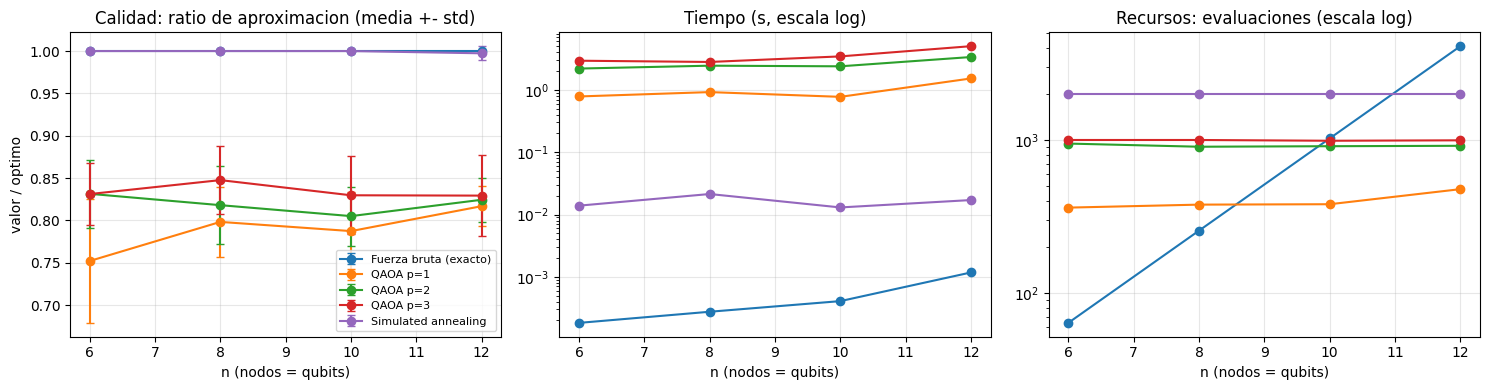

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for m, g in df.groupby("method"):
    s = g.groupby("n").agg(mean=("ratio", "mean"), std=("ratio", "std"),
                           t=("time", "mean"), ev=("evals", "mean"))
    axs[0].errorbar(s.index, s["mean"], yerr=s["std"], marker="o", capsize=3, label=m)
    axs[1].plot(s.index, s["t"], marker="o", label=m)
    axs[2].plot(s.index, s["ev"], marker="o", label=m)
axs[0].set_title("CALIDAD: ratio de aproximacion (media +- std)"); axs[0].set_ylabel("valor / optimo")
axs[1].set_title("TIEMPO (s, escala log)"); axs[1].set_yscale("log")
axs[2].set_title("RECURSOS: evaluaciones (escala log)"); axs[2].set_yscale("log")
for a in axs: a.set_xlabel("n (nodos = qubits)"); a.grid(alpha=.3)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

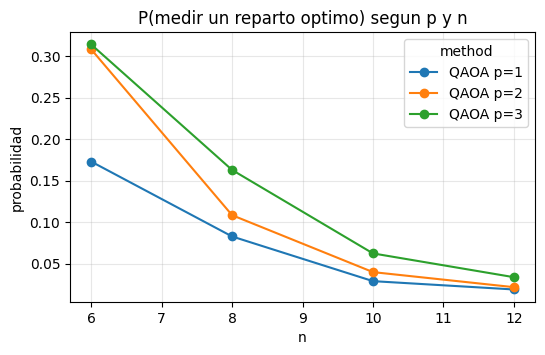

In [19]:
# Esta cuarta gráfica muestra la probabilidad de que una sola medida caiga en un reparto óptimo. Es más probable con p=3, siendo p es el número de capas que repite el circuito. Pero claro, más parámetros hacen el optimizador más difícil, y las sim más lentas.
q = df[df.method.str.startswith("QAOA")].groupby(["method", "n"])["p_opt"].mean().unstack(0)
ax = q.plot(marker="o", figsize=(6, 3.5), title="P(medir un reparto optimo) segun p y n")
ax.set_ylabel("probabilidad"); ax.grid(alpha=.3); plt.show()

## 6. Validacion cruzada con Qiskit

Construimos el **mismo** circuito con puertas de Qiskit y comprobamos que su distribucion de probabilidad
coincide con la de nuestro simulador NumPy. Es la prueba de que entendemos lo que hace la libreria.

Qiskit escribe los bitstrings con el qubit 0 a la derecha, asi que se invierte la cadena para compararla
con nuestra convencion (nodo 0 a la izquierda).

### 6.1 Conexión con IBM Quantum

In [20]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [21]:
!pip install -q qiskit-ibm-runtime
!pip install -q "python-dateutil<3.0,>=2.8.2"
# Ignorar el ERROR. Ocurre porque ibm_cloud_sdk_core necesita una versión más reciente de python, que la preinstalada por Colab.

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.107 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.46.2 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibm-cloud-sdk-core 3.28.1 requires python_dateutil<3.1.0,>=3.0.0, bu

In [22]:
import qiskit
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import userdata
ref1 = str(userdata.get('ref1'))

# Usamos la plataforma clásica de IBM Quantum, también podría ser ibm_cloud:
QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token=ref1, overwrite=True)

# Probamos a inicializarlo y listar los simuladores/backends disponibles
service = QiskitRuntimeService()
print("¡Conectado con éxito!")
print(service.backends())

qiskit_runtime_service.__init__:WARNING:2026-11-04 23:49:53,446: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Santiago-server. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-04 23:49:53,452: Loading instance: Santiago-server, plan: open


¡Conectado con éxito!
[<IBMBackend('ibm_fez')>, <IBMBackend('ibm_kingston')>, <IBMBackend('ibm_marrakesh')>]


Diferencia maxima entre NumPy y Qiskit: 1.6653345369377348e-16


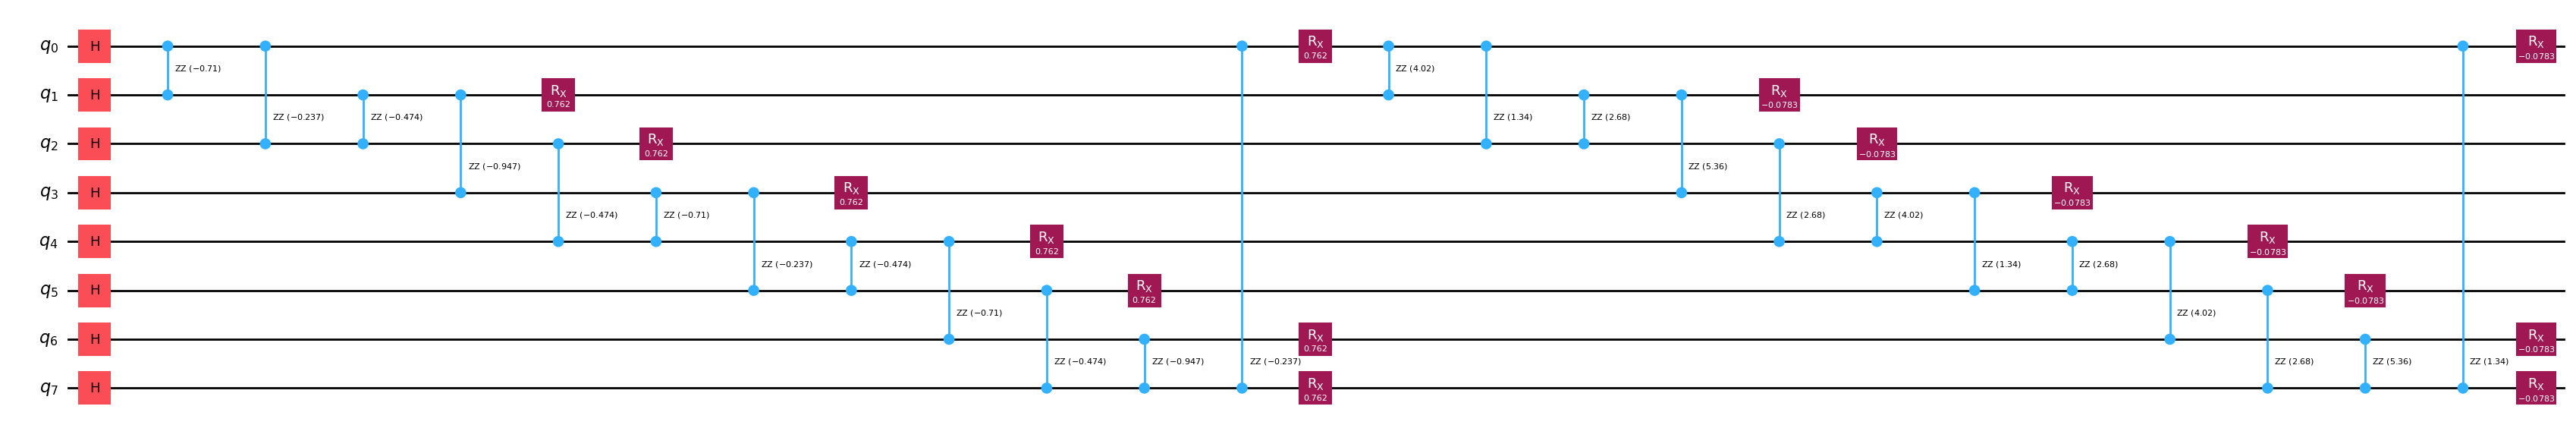

In [23]:
# !pip install qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

def qaoa_circuit(params, n, edges):
    p = len(params) // 2
    gammas, betas = params[:p], params[p:]
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for g, b in zip(gammas, betas):
        for i, j, w in edges:
            qc.rzz(2 * g * w, i, j)          # exp(-i g w Z_i Z_j)
        qc.rx(2 * b, range(n))               # exp(-i b X)
    return qc

r = run_qaoa(8, conflicts, p=2, seed=1)
qc = qaoa_circuit(r["params"], 8, conflicts)
qiskit_probs = Statevector(qc).probabilities_dict()
ours = r["probs"]
max_diff = max(abs(ours[int(bits[::-1], 2)] - pr) for bits, pr in qiskit_probs.items())
print("Diferencia maxima entre NumPy y Qiskit:", max_diff)
assert max_diff < 1e-9
qc.draw("mpl", fold=-1)

## 7. Conclusiones

10 grafos aleatorios por tamaño, $n = 6$–$12$ nodos (= cúbits), y un simulador ideal sin ruido.

1. **El clásico gana en calidad, tiempo y recursos.** Simulated annealing alcanza un ratio de $\approx 1.00$ en todos los tamaños. QAOA se queda en un corte esperado de $\approx 0.75$–$0.85$ del óptimo, y aun así es entre 100 y 300 veces más lento.

2. **QAOA sí hace algo útil: amplifica los buenos repartos.** La probabilidad de medir un óptimo es entre $\sim 5$ y $\sim 70$ veces mayor que muestreando al azar (que acierta con probabilidad $\approx 2/2^n$). Sin embargo, esa probabilidad **cae al crecer $n$**: con $p = 1$ pasa de $0.17$ ($n = 6$) a $0.02$ ($n = 12$).

3. **"La métrica en la tabla de el mejor de los 1024 shots $= 1.0$".** Esta métrica puede ser algo engañosa, ya que con solo entre 64 y 4096 estados, 1024 muestras casi recorren todo el espacio. No es prueba de ventaja. Las métricas honestas serían el ratio $\langle \text{cut} \rangle / \text{opt}$ y la probabilidad de óptimo frente al azar.

4. **Subir $p$ ayuda poco y de forma irregular.** De $p = 1$ a $p = 3$ el ratio pasa de $\sim 0.79$ a $\sim 0.83$–$0.85$, mientras que la probabilidad de óptimo mejora bastante más. Con $p = 3$ el optimizador agota su presupuesto (5 reinicios $\times$ 200 iteraciones $= 1000$ evaluaciones), así que no se puede concluir que $p = 3$ sea peor o igual que $p = 2$ en algún tamaño. Parte de la irregularidad es del optimizador y no del algoritmo.

5. **La fuerza bruta "gana" solo porque $n$ es muy pequeño** ($2^{12} = 4096$ casos). Su coste crece como $2^n$ y deja de ser viable hacia $n \sim 30$–$40$. El simulador de QAOA guarda $2^n$ amplitudes complejas (16 bytes cada una, $\approx 16$ GB con $n = 30$), así que se encuentra con el mismo muro exponencial, esta vez de memoria.

### Limitaciones del estudio

- **Simulación ideal:** sin ruido ni errores de medida. En hardware real la calidad bajaría al aumentar $p$ y la profundidad del circuito.
- **Alcance limitado:** tamaños pequeños y una sola familia de grafos (Erdős–Rényi, densidad $0.5$).
- **Tiempo simulado:** el tiempo de QAOA es de *simulación* en CPU, no mide el tiempo en un ordenador cuántico real.
- **Optimizador sin ajustar:** presupuesto fijo (COBYLA, 5 reinicios).
- **Evaluaciones no equivalentes:** una evaluación de simulated annealing es mucho más barata que una de QAOA, así que esa columna es una comparación aproximada de recursos.

### Trabajo futuro

- **Ruido:** modelo de ruido (Qiskit Aer) y mitigación de errores (ZNE).
- **Más variedad:** otras familias de grafos (regulares) y tamaños mayores.
- **Optimización:** más presupuesto y otros optimizadores (SPSA).
- **Más allá de $\sim 20$ cúbits:** VQE y simulador MPS (redes tensoriales).